<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_9/dataset_pbl/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 2**

Pada percobaan ini kita akan menggunakan dataset **Sleep Health and Lifestyle** untuk membuat model klasifikasi Naive Bayes dengan target prediksi ada tidaknya gangguan tidur (`Normal` vs `Gangguan Tidur`) berdasarkan fitur **Durasi Tidur** (`Sleep Duration`) dan **Tingkat Stres** (`Stress Level`). Selanjutnya, kita akan membandingkan performa model **Multinomial Naive Bayes** menggunakan `MultinomialNB` dan model **Gaussian Naive Bayes** menggunakan `GaussianNB`.

## **Langkah 1 - Load Data**

In [1]:
import numpy as np
import pandas as pd

# Baca dataset Sleep Health
raw_data = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
raw_data['Sleep Disorder'] = raw_data['Sleep Disorder'].fillna('None')

# Ambil 2 fitur utama (Sleep Duration & Stress Level) dan ubah label menjadi 2 kelas (0 = Normal, 1 = Gangguan Tidur)
X = raw_data[['Sleep Duration', 'Stress Level']].values
y = np.where(raw_data['Sleep Disorder'] == 'None', 0, 1)

print("Contoh fitur X:\n", X[:5])
print("Contoh label y:\n", y[:5])

Contoh fitur X:
 [[6.1 6. ]
 [6.2 8. ]
 [6.2 8. ]
 [5.9 8. ]
 [5.9 8. ]]
Contoh label y:
 [0 0 0 1 1]


Penjelasan variabel yang diambil dari dataset **Sleep Health and Lifestyle**:
* **Sleep Duration**: Lama waktu tidur harian individu dalam satuan jam (fitur pertama).
* **Stress Level**: Tingkat stres harian individu pada skala 1 hingga 10 (fitur kedua).
* **Sleep Disorder (Target `y`)**: Dikonversi menjadi klasifikasi biner, yaitu `0` untuk kondisi **Normal** (*None*) dan `1` untuk kondisi **Gangguan Tidur** (*Insomnia* maupun *Sleep Apnea*).

## **Langkah 2 (Opsional) - Membuat Data Frame**
Agar data lebih mudah untuk dibaca, maka kita akan membuat DataFrame dengan menggunakan library Pandas berdasarkan data dummy yang telah dibuat sebelumnya.

In [2]:
y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)

nama_kolom = ['Sleep Duration', 'Stress Level', 'Label']
df = pd.DataFrame(data, columns=nama_kolom)
df['Label'] = df['Label'].astype(int)

df.head()

,Sleep Duration,Stress Level,Label
0,6.1,6.0,0
1,6.2,8.0,0
2,6.2,8.0,0
3,5.9,8.0,1
4,5.9,8.0,1


## **Langkah 3 (Opsional) - Labeling**
 Dikarenakan label masih berbetuk encoding angka, untuk mempermudah pembacaan data, kita dapat mengubah bentuknya dalam bentuk kategorial

In [3]:
labels = {
    1: 'Gangguan Tidur',
    0: 'Normal'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

df_label.head()

,Sleep Duration,Stress Level,Label
0,6.1,6.0,Normal
1,6.2,8.0,Normal
2,6.2,8.0,Normal
3,5.9,8.0,Gangguan Tidur
4,5.9,8.0,Gangguan Tidur


## **Langkah 4 - Visualisasi Data**

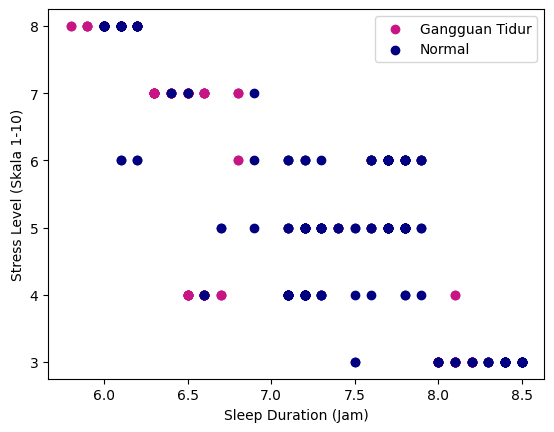

In [4]:
import matplotlib.pyplot as plt

colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

gb = df_label.groupby(['Label'])
class_a = gb.get_group(('Gangguan Tidur',))
class_b = gb.get_group(('Normal',))

plt.scatter(x=class_a['Sleep Duration'], y=class_a['Stress Level'], c=colors['class_a'])
plt.scatter(x=class_b['Sleep Duration'], y=class_b['Stress Level'], c=colors['class_b'])
plt.xlabel('Sleep Duration (Jam)')
plt.ylabel('Stress Level (Skala 1-10)')
plt.legend(['Gangguan Tidur', 'Normal'])
plt.show()

## **Langkah 5 - Model Multinomial Nave Bayes**
Selanjutnya kita membuat model Naive Bayes menggunakan algoritma Multinomial (`MultinomialNB`). Secara teori, model multinomial dirancang untuk fitur yang bersifat diskrit (seperti frekuensi kata pada klasifikasi teks). Pada percobaan ini, model tersebut diujicobakan pada fitur numerik dataset *Sleep Health* sebagai bahan perbandingan performa.

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

mnb.fit(X_train, y_train)

y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.6015325670498084
Hasil akurasi data test: 0.584070796460177


## **Langkah 6 - Model Gaussian Naive Bayes**
Model Gaussian (`GaussianNB`) lebih sesuai untuk fitur numerik kontinu seperti durasi tidur dan tingkat stres karena mengasumsikan data mengikuti distribusi normal (Gaussian).

In [6]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.7011494252873564
Hasil akurasi data test (Gaussian): 0.7079646017699115


Berdasarkan perbandingan kedua model di atas, **Gaussian Naive Bayes** memberikan pendekatan yang lebih tepat secara teoritis untuk memproses fitur numerik kontinu pada dataset *Sleep Health and Lifestyle* dibandingkan dengan **Multinomial Naive Bayes**.